[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/grabuffo/brain-modeling-course/blob/main/notebooks/D2_C5_NB14b_stimulation_spread.ipynb)

# Day 2 · Chapter 5 · Notebook 14b — Stimulation: following a push through the connectome

We push one region of the Hopf model (NB10) for 2 seconds and follow where the push goes: which regions feel it, how
strongly, for how long.

> **Question.** Where does a local stimulation go, and what decides how far it travels?
> **Virtual experiment.** The same brain at the same moment, with and without a push to one region.
> **What would change our mind.** If the response did not depend on the wiring, or not on the distance to the
> bifurcation (the state of the brain).

**The trick that makes it a perfect controlled experiment.** We run the model twice with **exactly the same noise**,
once with the push and once without, and subtract: what remains is the **response** to the push and nothing else.
In a real brain this is impossible (the same brain, at the same moment, with and without stimulation). We average
over 3 noise seeds.

<details><summary>What the push is</summary>

An input added to the equation of one region of the Hopf model during 2 s: a perturbation of the model, not a model of
a TMS coil or an electrode. Working point of NB13: $a=-0.1$, $G=2$.
</details>

In [1]:
# @title Setup (run once)
# On Google Colab this downloads the course code; on your laptop it does nothing.
import sys, os
if "google.colab" in sys.modules:
    if not os.path.exists("/content/brain-modeling-course"):          # first run: download the course code
        !git clone -q https://github.com/grabuffo/brain-modeling-course.git /content/brain-modeling-course
        !pip -q install numba ipywidgets
    %cd /content/brain-modeling-course/notebooks
sys.path.insert(0, os.path.abspath(".."))   # so that `import src` works

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact
from src import plotting
from src.plotting import slider
plotting.setup()
from src import connectome
sc, fc, labels = connectome.load_hcp(weights="counts", normalize="rowsum", homotopic=0.5)   # same connectome as NB10
labels = [l.replace("7Networks_", "") for l in labels]
W = sc + sc.T                                                       # connection weight between two regions
strength = W.sum(1)

def simulate(a, G, target=None, push=0.0, t_on=10.0, dur=2.0, seconds=60.0, sigma=0.02, seed=0, f=0.05, dt=0.1):
    # Hopf whole-brain model (NB10), sampled every dt; a push of size `push` to region `target` from t_on to t_on + dur
    rng = np.random.default_rng(seed)
    N = len(sc); s = sc.sum(1); omega = 2 * np.pi * f
    z = 0.1 * (rng.standard_normal(N) + 1j * rng.standard_normal(N))
    out = []
    for k in range(int((60 + seconds) / dt)):                       # the first minute is discarded
        t = k * dt - 60
        I = np.zeros(N)
        if target is not None and t_on <= t < t_on + dur:
            I[target] = push
        z = z + dt * ((a + 1j * omega) * z - np.abs(z) ** 2 * z + G * (sc @ z - s * z) + I) \
              + sigma * np.sqrt(dt) * (rng.standard_normal(N) + 1j * rng.standard_normal(N))
        if t >= 0:
            out.append(z.copy())                                    # complex: real part = activity, modulus = envelope
    return np.array(out)

def response(a, target, G=2.0, push=0.5, seeds=3):
    # stimulated minus not stimulated, same noise; averaged over a few noise seeds (complex: use .real or np.abs)
    return np.mean([simulate(a, G, target, push, seed=s) - simulate(a, G, seed=s) for s in range(seeds)], axis=0)

dt = 0.1; t = np.arange(int(60 / dt)) * dt
hub = int(np.argmax(strength))
print("stimulated region:", labels[hub], "(the strongest hub)")

stimulated region: RH_SalVentAttn_FrOperIns_1 (the strongest hub)


## 1. One push, followed in time

The stimulated region responds strongly; its neighbours respond later and more weakly; regions far away in the network
barely notice. Then everything relaxes back.

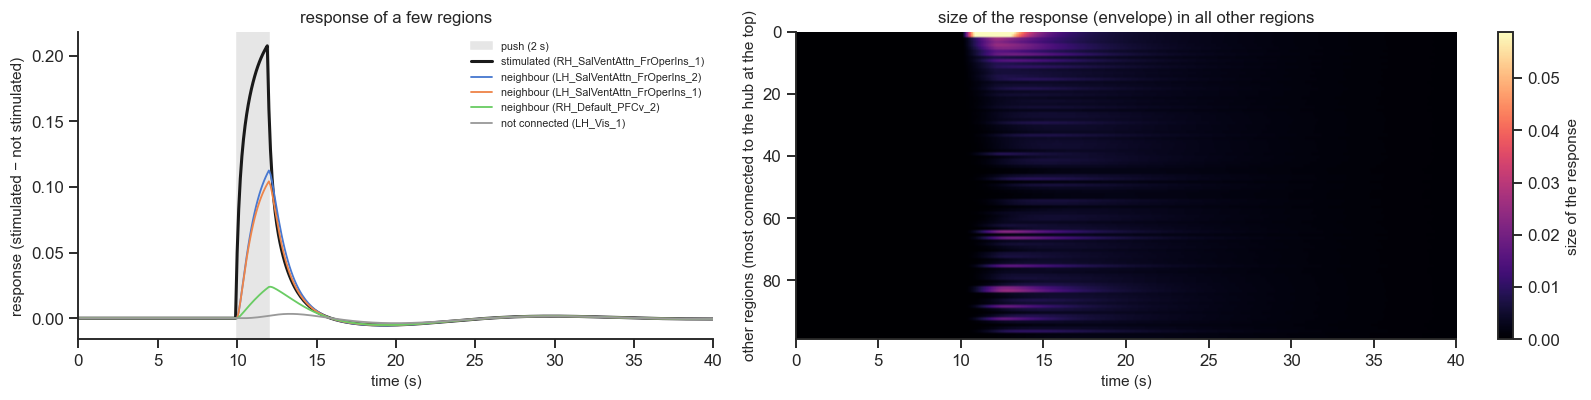

In [2]:
# @title Push the strongest hub for 2 s and follow the response of every region
R = response(-0.1, hub)
others = np.setdiff1d(np.arange(100), [hub])
near = others[np.argsort(-W[hub, others])[:3]]; far = others[np.argsort(W[hub, others])[:1]]
fig, ax = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw=dict(width_ratios=[1, 1.3]))
ax[0].axvspan(10, 12, color="0.9", label="push (2 s)")
ax[0].plot(t, R[:, hub].real, "k", lw=2, label=f"stimulated ({labels[hub]})")
for i in near: ax[0].plot(t, R[:, i].real, lw=1.2, label=f"neighbour ({labels[i]})")
ax[0].plot(t, R[:, far[0]].real, "0.6", lw=1.2, label=f"not connected ({labels[far[0]]})")
ax[0].set(xlabel="time (s)", ylabel="response (stimulated − not stimulated)", xlim=(0, 40), title="response of a few regions"); ax[0].legend(fontsize=7)
srt = others[np.argsort(-W[hub, others])]
im = ax[1].imshow(np.abs(R[:, srt]).T, aspect="auto", cmap="magma", extent=[0, 60, len(srt), 0],
                  vmax=np.abs(R[:, srt]).max() * 0.5)
ax[1].set(xlabel="time (s)", ylabel="other regions (most connected to the hub at the top)", xlim=(0, 40),
          title="size of the response (envelope) in all other regions"); plt.colorbar(im, ax=ax[1], label="size of the response")
plt.tight_layout(); plt.show()

Left: the signed response; right: its size (the envelope of the oscillation). The response is largest in the regions most
strongly wired to the hub (top rows; the two strongest "neighbours" are the mirror regions in the other hemisphere),
and it arrives delayed and smoothed: each region filters the push with its own slow dynamics before passing it on.
Some weakly wired regions (bright rows further down) also respond, reached in two or more steps.

## 2. Where does the push go? The wiring decides

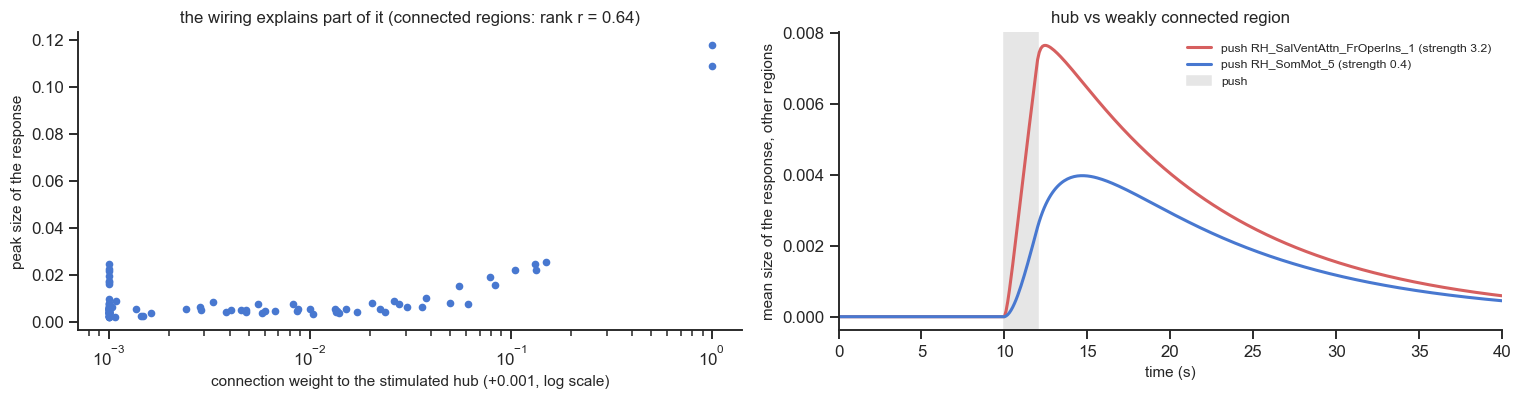

In [3]:
# @title Peak response vs connection weight; and stimulating the hub vs the most weakly connected region
peak = np.abs(R).max(0)
weak = int(np.argmin(strength))
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
wk = W[hub, others]; con = wk > 0                                   # regions directly wired to the hub
rho = np.corrcoef(np.argsort(np.argsort(wk[con])), np.argsort(np.argsort(peak[others][con])))[0, 1]   # rank correlation
ax[0].plot(wk + 1e-3, peak[others], "o", ms=4); ax[0].set_xscale("log")
ax[0].set(xlabel="connection weight to the stimulated hub (+0.001, log scale)", ylabel="peak size of the response",
          title=f"the wiring explains part of it (connected regions: rank r = {rho:.2f})")
for k, c in [(hub, "C3"), (weak, "C0")]:
    Rk = R if k == hub else response(-0.1, k); o = np.setdiff1d(np.arange(100), [k])
    ax[1].plot(t, np.abs(Rk[:, o]).mean(1), c=c, lw=2, label=f"push {labels[k]} (strength {strength[k]:.1f})")
ax[1].axvspan(10, 12, color="0.9", label="push")
ax[1].set(xlabel="time (s)", ylabel="mean size of the response, other regions", xlim=(0, 40), title="hub vs weakly connected region")
ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

Among the regions wired to the hub, the stronger the wire, the larger the response (the two points at the right are
the mirror regions). But the regions at the far left are **not** wired to the hub and respond as much as many wired
ones: direct wiring explains part of the response, indirect paths matter as much. At its peak, a push to the hub reaches the rest of the
brain about twice as strongly as the same push to the most weakly connected region.

## 3. How far does it travel? The distance to the bifurcation decides

Close to the bifurcation a region amplifies and prolongs what it receives (critical slowing down, NB08), so it relays the
push further and longer. This is the model version of the TMS experiment of the slides (perturbational complexity):
in wakefulness a pulse spreads widely, in deep sleep it stays local. Here the "state" is the distance to the bifurcation.

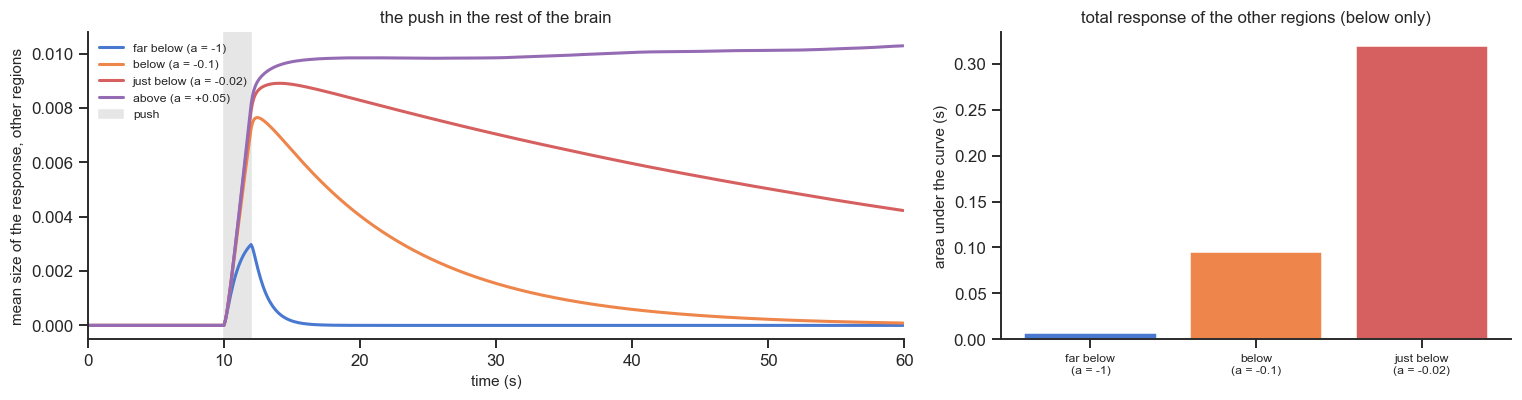

total response relative to a = -1: ['1.0x', '13.5x', '45.3x']


In [4]:
# @title Same push to the hub, with all regions at four distances from the bifurcation (three below, one above)
cases = [(-1.0, "far below (a = -1)", "C0"), (-0.1, "below (a = -0.1)", "C1"), (-0.02, "just below (a = -0.02)", "C3"),
         (0.05, "above (a = +0.05)", "C4")]
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw=dict(width_ratios=[1.6, 1]))
total = []
for a, name, c in cases:
    Ra = R if a == -0.1 else response(a, hub); spread = np.abs(Ra[:, others]).mean(1)
    ax[0].plot(t, spread, c=c, lw=2, label=name)
    if a < 0:                                                        # below: the response ends, so its total is finite
        total.append(spread.sum() * dt); ax[1].bar(name.replace(" (", "\n("), total[-1], color=c)
ax[0].axvspan(10, 12, color="0.9", label="push")
ax[0].set(xlabel="time (s)", ylabel="mean size of the response, other regions", xlim=(0, 60), title="the push in the rest of the brain"); ax[0].legend(fontsize=8)
ax[1].set(ylabel="area under the curve (s)", title="total response of the other regions (below only)"); ax[1].tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()
print("total response relative to a = -1:", [f"{x / total[0]:.1f}x" for x in total])

Same push, same wiring: just below the bifurcation the rest of the brain receives tens of times more of it than far
below, and it lingers much longer. The working point sets how far a local stimulation travels, one reason why the effect of
stimulation depends on the **state** of the brain.

**Above the bifurcation (purple) the response never ends.** Every region oscillates, and the coupling locks them into
one shared rhythm. The push does not add lasting activity: the size of the oscillations returns to normal. But it
shifts the **timing** of the whole rhythm (by about 2°, the same in every region), and nothing pulls the rhythm back.
So the stimulated brain stays out of step with the unstimulated one forever. Below the bifurcation a push is an
**echo** that fades in about $1/|a|$; above it, a push **resets the clock** of the rhythm.

### Explore: target, distance to the bifurcation, size of the push (a few seconds per change)

In [5]:
# @title Explore: choose the stimulated region, a and the size of the push
@interact(region=[(labels[i], i) for i in np.argsort(-strength)],                    # region names, strongest first
          a=slider(-0.1, -1.0, -0.01, 0.01, "distance to bifurcation a"),
          push=slider(0.5, 0.1, 2.0, 0.1, "size of the push"))
def explore_stimulation(region, a, push):
    region = int(region)                                              # sliders/dropdowns may give decimals
    Rk = response(a, region, push=push, seeds=1); o = np.setdiff1d(np.arange(100), [region])
    srt = o[np.argsort(-W[region, o])]
    fig, ax = plt.subplots(1, 2, figsize=(14, 3.6), gridspec_kw=dict(width_ratios=[1, 1.3]))
    ax[0].plot(t, Rk[:, region].real, "k", lw=2, label="stimulated"); ax[0].plot(t, np.abs(Rk[:, o]).mean(1) * 10, "C3", label="other regions: mean size × 10")
    ax[0].axvspan(10, 12, color="0.9", label="push"); ax[0].set(xlabel="time (s)", ylabel="response", title=labels[region]); ax[0].legend(fontsize=8)
    im = ax[1].imshow(np.abs(Rk[:, srt]).T, aspect="auto", cmap="magma", extent=[0, 60, len(srt), 0])
    ax[1].set(xlabel="time (s)", ylabel="other regions (most connected first)", title="size of the response, all other regions"); plt.colorbar(im, ax=ax[1], label="size of the response")
    plt.tight_layout(); plt.show()

## Take-home

* Same brain, same noise, with and without the push: a controlled experiment that is impossible in a real brain.
* A push to one region travels through the connectome, **strongest along the strongest wires** and also along indirect
  paths, delayed and smoothed.
* Pushing a **hub** reaches the rest of the brain more strongly than pushing a weakly connected region.
* **Close to the bifurcation** the push spreads further and lasts longer: the state of the brain decides how far it
  reaches, as in the TMS experiments of the slides. **Above** it, the push shifts the timing of the shared rhythm for good.
* **Next (NB14c):** with bistable regions, a local change can do much more than a push: a seizure.

### Homework
*To do at home, after the class.*
1. **Two steps away.** Find regions that are not directly connected to the hub but are connected to its neighbours.
   Do they respond? Later than the direct neighbours?
2. **Beyond the bifurcation.** At $a=+0.05$, is the lasting response proportional to the push? (Try push sizes 0.25,
   0.5, 1.) Measure the phase shift with `np.angle(z_stim * np.conj(z_nostim))`.
3. **Stimulation and FC.** Is the region that responds most to the push also the one most correlated with the hub at
   rest (the FC of NB10)? Compare the response profile with the hub's row of the model FC.

### References
* Deco G, Kringelbach ML, Jirsa VK, Ritter P (2017). The dynamics of resting fluctuations in the brain: metastability and
  its dynamical cortical core. *Sci Rep* 7:3095.
* Honey CJ, Kötter R, Breakspear M, Sporns O (2007). Network structure of cerebral cortex shapes functional connectivity
  on multiple time scales. *PNAS* 104:10240–10245.